# Прогноз продаж на неделю

Сравниваю CatBoost с простым прогнозом, который повторяет продажи прошлой недели. Беру продажи категории FOODS в магазине Walmart CA_1 из [данных M5](https://github.com/Mcompetitions/M5-methods). Прогнозирую, сколько штук продаст магазин в каждый из следующих семи дней.

In [1]:
from pathlib import Path
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

root = Path.cwd().resolve()
if not (root / "forecast.py").is_file():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from forecast import backtest, load_sales

sales = load_sales(root / "data" / "sales.csv")
predictions = backtest(sales, n_weeks=12)

## Проверка по неделям

Проверяю прогноз на последних 12 неделях. Перед каждой неделей заново обучаю CatBoost на данных до её начала и прогнозирую сразу на семь дней. В модели использую день недели, отметку о событии в календаре M5 и продажи за 7, 14 и 28 дней до прогнозируемой даты. Все эти продажи уже известны к началу недели. События беру из календаря и считаю известными заранее.

MAE показывает среднюю ошибку прогноза в штуках за день. Чем меньше MAE, тем точнее прогноз.

In [2]:
method_labels = {"seasonal_naive": "Прошлая неделя", "catboost": "CatBoost"}
absolute_errors = predictions[list(method_labels)].sub(predictions["actual"], axis=0).abs()
weekly_mae = absolute_errors.groupby(predictions["week_start"]).mean()
overall_mae = absolute_errors.mean()

score_table = weekly_mae.rename(columns=method_labels)
score_table.index = score_table.index.strftime("%d.%m.%Y")
score_table.loc["Все дни"] = overall_mae.rename(index=method_labels)
display(score_table.rename_axis("Неделя с").round(1))

,Прошлая неделя,CatBoost
Неделя с,,
29.02.2016,204.4,135.1
07.03.2016,264.4,149.7
14.03.2016,270.9,204.8
21.03.2016,448.3,378.8
28.03.2016,337.4,159.7
04.04.2016,306.3,245.4
11.04.2016,315.1,127.6
18.04.2016,123.4,94.1
25.04.2016,102.1,267.3


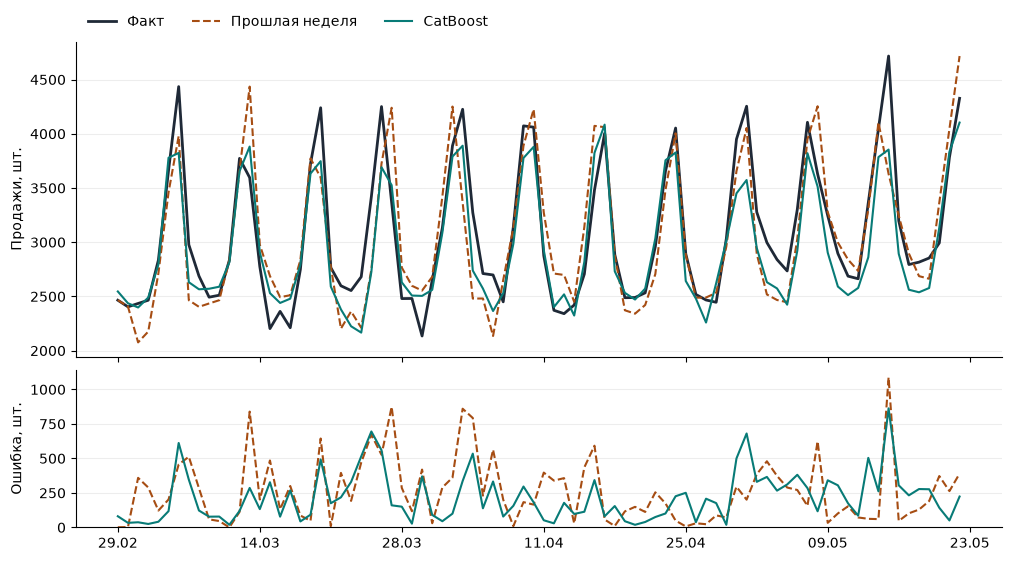

In [3]:
colors = {"seasonal_naive": "#A64D13", "catboost": "#087B77"}
styles = {"seasonal_naive": "--", "catboost": "-"}
dates = predictions["date"]

fig, (sales_ax, error_ax) = plt.subplots(
    2, 1, figsize=(10, 5.5), height_ratios=(2, 1), sharex=True, layout="constrained"
)
sales_ax.plot(dates, predictions["actual"], color="#1F2937", linewidth=2, label="Факт")

for method, label in method_labels.items():
    style = {"color": colors[method], "linestyle": styles[method], "linewidth": 1.5}
    sales_ax.plot(dates, predictions[method], label=label, **style)
    error_ax.plot(dates, absolute_errors[method], **style)

sales_ax.set_ylabel("Продажи, шт.")
error_ax.set_ylabel("Ошибка, шт.")
error_ax.set_ylim(bottom=0)
sales_ax.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=3, frameon=False)
error_ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=2))
error_ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))

for ax in (sales_ax, error_ax):
    ax.grid(axis="y", alpha=0.22)
    ax.spines[["top", "right"]].set_visible(False)

plt.show()

## Где прогноз ошибается

Сравниваю среднюю ошибку в дни с отметкой о событии в календаре M5 и в остальные дни.

In [4]:
event_labels = predictions["is_event"].map({0: "Без события", 1: "С событием"})
event_mae = absolute_errors.groupby(event_labels).mean().rename(columns=method_labels)
event_mae.insert(0, "Дней", event_labels.value_counts())
display(event_mae.rename_axis("Календарь M5").round(1))

worst_index = absolute_errors["catboost"].idxmax()
worst = predictions.loc[worst_index]
display(Markdown(
    f"Самый большой промах CatBoost пришёлся на **{worst['date']:%d.%m.%Y}**. "
    f"Модель предсказала {worst['catboost']:.0f} шт., а магазин продал {worst['actual']:.0f} шт. "
    f"Неделей раньше в тот же день продали {worst['seasonal_naive']:.0f} шт."
))

,Дней,Прошлая неделя,CatBoost
Календарь M5,,,
Без события,77,249.3,206.3
С событием,7,436.1,364.4


Самый большой промах CatBoost пришёлся на **15.05.2016**. Модель предсказала 3854 шт., а магазин продал 4717 шт. Неделей раньше в тот же день продали 3630 шт.

In [5]:
wins = weekly_mae["catboost"].lt(weekly_mae["seasonal_naive"]).sum()
catboost_mae = f"{overall_mae['catboost']:.1f}".replace(".", ",")
baseline_mae = f"{overall_mae['seasonal_naive']:.1f}".replace(".", ",")
display(Markdown(
    "## Итог\n\n"
    f"CatBoost в среднем ошибался на **{catboost_mae} шт. в день**, "
    f"а прогноз по прошлой неделе на **{baseline_mae} шт.** "
    f"CatBoost оказался точнее в {wins} из {len(weekly_mae)} недель."
))

## Итог

CatBoost в среднем ошибался на **219,5 шт. в день**, а прогноз по прошлой неделе на **264,8 шт.** CatBoost оказался точнее в 9 из 12 недель.